# Experiment 9: From a Still Render to a Short Video

Render tools now offer **"still to video"**: the user's render becomes a short clip with a slow camera move. Image-to-video models generate many connected frames at once, but as the clip goes on they can **drift**: furniture changes shape, windows bend, shelf objects flicker from frame to frame. For an architect, a video that changes the design is a problem.

| Method | What it is |
|---|---|
| **A: Depth parallax** | No generative model. Depth Anything V2 estimates depth, and the image is warped so near objects move more than far ones while the camera slowly moves in. Faithful by construction, but only a 2.5D effect. |
| **B: SVD, low motion** | Stable Video Diffusion img2vid-xt (25 frames), `motion_bucket_id = 40` |
| **C: SVD, default motion** | The same model, `motion_bucket_id = 127` (its default) |

**Metrics.** Because the camera moves, a frame cannot be compared with the first frame pixel by pixel. I estimate the motion between frames with optical flow (OpenCV Farnebäck), warp the frames back onto each other, and then measure:

| Metric | What it tells | Better |
|---|---|---|
| **Motion** | Average movement between consecutive frames (pixels at 512 px width) | depends: more = livelier |
| **Flicker** | Mean ΔE between a frame and the next frame warped back onto it: changes that are not explained by camera motion | lower |
| **Drift ΔE** | Mean ΔE between the first and the last frame, after warping: how much the colors and materials changed over the clip | lower |
| **Drift edge recall** | Share of the first frame's edges still in the warped last frame | higher |
| **First frame ΔE** | How much the video's first frame differs from the input render | lower |
| **Sec/video, peak memory** | Cost on a free T4 GPU | lower |

## 1. Setup

In [1]:
!pip uninstall -y torchao
!pip install -q diffusers transformers accelerate opencv-python

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 2. Check the GPU (must print True and Tesla T4)

In [2]:
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))

2.11.0+cu130 True Tesla T4


## 3. Log in to Hugging Face
Stable Video Diffusion is a **gated** model: open [its page](https://huggingface.co/stabilityai/stable-video-diffusion-img2vid-xt), log in and accept the license first. Then create a **read** token in your Hugging Face settings and paste it in the box below. The token is not saved in the notebook, but check the outputs for `hf_` before uploading the notebook anywhere.

In [3]:
from huggingface_hub import notebook_login
notebook_login()

## 4. Upload room photos
Upload **3 interior photos** (one SVD video takes a few minutes on a T4). Each photo is center-cropped to 16:9 and resized to 1024×576, the size SVD was trained on.

In [4]:
import io, gc, time, cv2, numpy as np, pandas as pd
from PIL import Image
from IPython.display import Image as IPImage
from google.colab import files

W, H = 1024, 576
uploaded = files.upload()
images = sorted(uploaded)

def crop_16_9(img):
    w, h = img.size; target = 16 / 9
    if w / h > target:
        nw = int(h * target); x = (w - nw) // 2; return img.crop((x, 0, x + nw, h))
    nh = int(w / target); y = (h - nh) // 2; return img.crop((0, y, w, y + nh))

stills = {n: crop_16_9(Image.open(name).convert("RGB")).resize((W, H), Image.LANCZOS)
          for n, name in enumerate(images, start=1)}
print(list(stills))

def show(img, max_w=1600):
    im = img.copy(); im.thumbnail((max_w, max_w))
    buf = io.BytesIO(); im.save(buf, format="JPEG", quality=85); display(IPImage(data=buf.getvalue()))

Saving living-room.jpg to living-room.jpg
Saving open-plan.jpg to open-plan.jpg
Saving room.jpg to room.jpg
[1, 2, 3]


## 5. Method A: depth parallax
The camera moves in by 6% and slightly to the side; each pixel moves in proportion to how close it is.

In [5]:
from transformers import pipeline as hf_pipeline

N_FRAMES = 25
depth_est = hf_pipeline("depth-estimation", model="depth-anything/Depth-Anything-V2-Small-hf", device=0)

def depth_map(img):
    d = np.array(depth_est(img)["depth"].resize(img.size)).astype(np.float32)
    return (d - d.min()) / (d.max() - d.min() + 1e-6)              # 1 = near, 0 = far

def parallax(img, depth, n=N_FRAMES, shift=28, zoom=0.06):
    a = np.array(img); h, w = a.shape[:2]
    ys, xs = np.mgrid[0:h, 0:w].astype(np.float32)
    out = []
    for i in range(n):
        t = i / (n - 1); s = 1 + zoom * t
        mx = (xs - w / 2) / s + w / 2 - shift * t * (depth - 0.5)  # near pixels move more
        my = (ys - h / 2) / s + h / 2
        out.append(Image.fromarray(cv2.remap(a, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)))
    return out

videos, perf = {}, []
for n, img in stills.items():
    t = time.time()
    videos[("A: Depth parallax", n)] = parallax(img, depth_map(img))
    perf.append({"method": "A: Depth parallax", "room": n, "sec/video": time.time() - t, "peak GB": np.nan})
del depth_est; gc.collect(); torch.cuda.empty_cache()
print("parallax done")

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

parallax done


## 6. Methods B and C: Stable Video Diffusion
Memory savers keep SVD under the T4's 15 GB: CPU offload, UNet forward chunking and decoding two frames at a time. Each video takes a few minutes.

In [6]:
from diffusers import StableVideoDiffusionPipeline

svd = StableVideoDiffusionPipeline.from_pretrained(
    "stabilityai/stable-video-diffusion-img2vid-xt", torch_dtype=torch.float16, variant="fp16")
svd.enable_model_cpu_offload()
svd.unet.enable_forward_chunking()
svd.set_progress_bar_config(disable=True)

SVD = {"B: SVD, low motion": 40, "C: SVD, default motion": 127}
for name, motion in SVD.items():
    for n, img in stills.items():
        torch.cuda.reset_peak_memory_stats(); t = time.time()
        frames = svd(img, num_frames=N_FRAMES, num_inference_steps=25, motion_bucket_id=motion,
                     noise_aug_strength=0.02, decode_chunk_size=2,
                     generator=torch.manual_seed(42)).frames[0]
        videos[(name, n)] = [f.resize((W, H)) for f in frames]
        perf.append({"method": name, "room": n, "sec/video": time.time() - t,
                     "peak GB": torch.cuda.max_memory_allocated() / 1e9})
        print(f"{name}, room {n}: {time.time() - t:.0f} s")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/496 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/520 [00:00<?, ?it/s]

... (8 outputs left out)

There are modules in AutoencoderKLTemporalDecoder that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKLTemporalDecoder that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKLTemporalDecoder that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


C: SVD, default motion, room 2: 387 s


There are modules in AutoencoderKLTemporalDecoder that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKLTemporalDecoder that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKLTemporalDecoder that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


C: SVD, default motion, room 3: 387 s


## 7. Look at the videos
For each room: a side-by-side GIF (A | B | C) and a strip of the first, middle and last frame of each method.

room 1: A: depth parallax | B: SVD low motion | C: SVD default motion


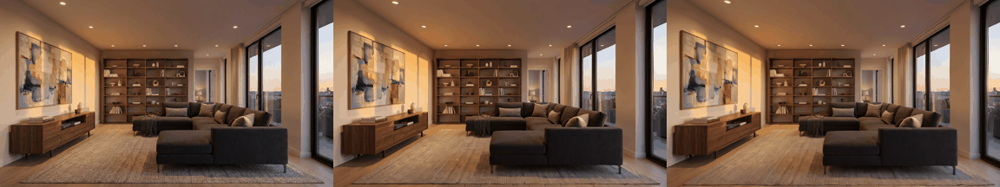

  rows: A, B, C · columns: first, middle, last frame


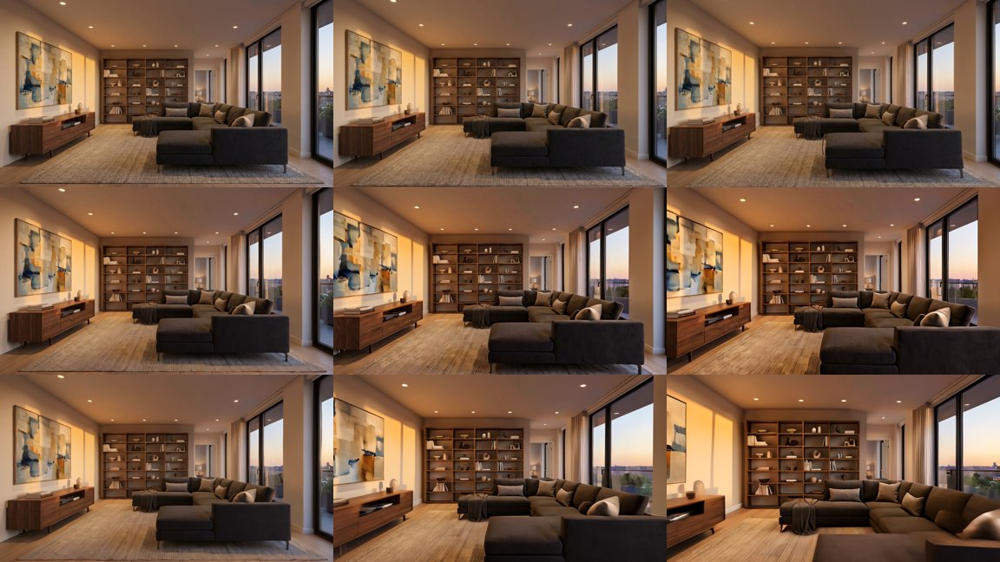

room 2: A: depth parallax | B: SVD low motion | C: SVD default motion


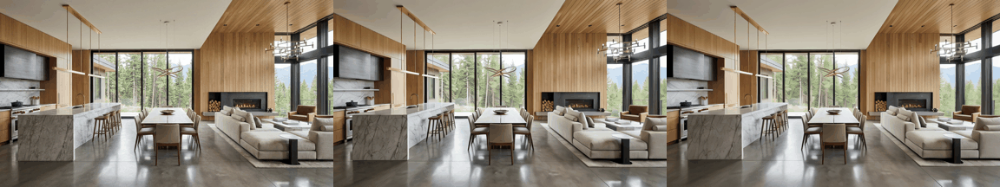

  rows: A, B, C · columns: first, middle, last frame


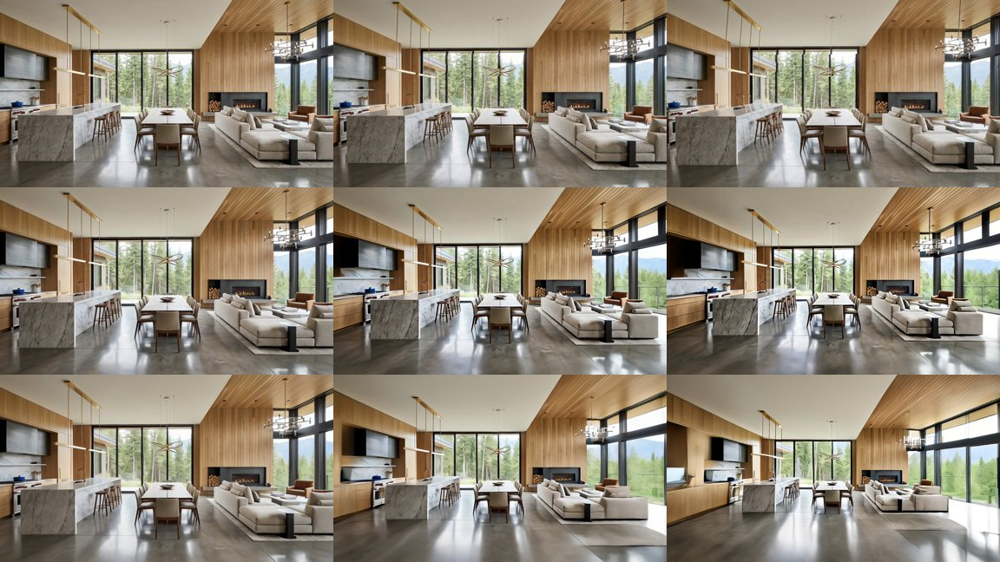

room 3: A: depth parallax | B: SVD low motion | C: SVD default motion


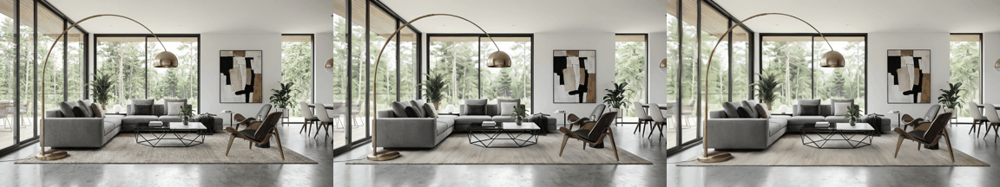

  rows: A, B, C · columns: first, middle, last frame


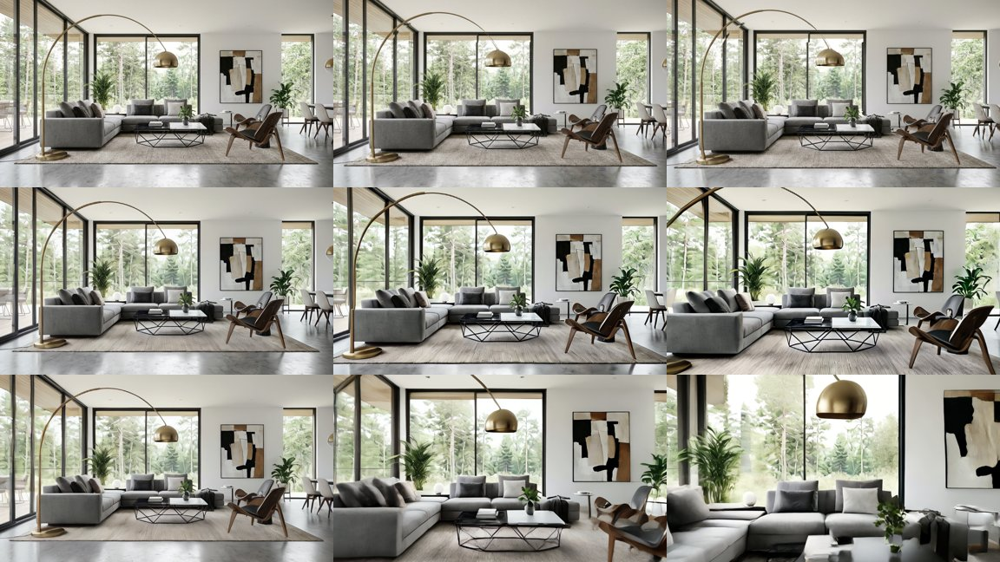

In [7]:
NAMES = ["A: Depth parallax", "B: SVD, low motion", "C: SVD, default motion"]

def side_by_side(frames_list, w=384, h=216):
    out = []
    for i in range(N_FRAMES):
        row = Image.new("RGB", (w * len(frames_list), h), "white")
        for j, fr in enumerate(frames_list): row.paste(fr[i].resize((w, h)), (j * w, 0))
        out.append(row)
    return out

for n in stills:
    gif = side_by_side([videos[(m, n)] for m in NAMES])
    path = f"exp9_room{n}_compare.gif"
    gif[0].save(path, save_all=True, append_images=gif[1:], duration=143, loop=0)       # 7 fps
    print(f"room {n}: A: depth parallax | B: SVD low motion | C: SVD default motion")
    display(IPImage(filename=path))
    keys = [0, N_FRAMES // 2, N_FRAMES - 1]
    rows = Image.new("RGB", (384 * 3, 216 * 3), "white")
    for r, m in enumerate(NAMES):
        for c, k in enumerate(keys): rows.paste(videos[(m, n)][k].resize((384, 216)), (c * 384, r * 216))
    print("  rows: A, B, C · columns: first, middle, last frame"); show(rows)
    rows.save(f"exp9_room{n}_frames.jpg", quality=90)

## 8. Measure

In [8]:
from skimage.color import rgb2lab, deltaE_ciede2000

SW, SH = 512, 288                         # measure at this size
B = 20                                    # ignore a border, where warping has no data
def small(img): return np.array(img.resize((SW, SH), Image.LANCZOS))
def gray(a): return cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)
def flow(a, b): return cv2.calcOpticalFlowFarneback(gray(a), gray(b), None, 0.5, 4, 21, 3, 5, 1.1, 0)
def warp_back(b, fl):                     # bring frame b into the coordinates of frame a
    ys, xs = np.mgrid[0:SH, 0:SW].astype(np.float32)
    return cv2.remap(b, xs + fl[..., 0], ys + fl[..., 1], cv2.INTER_LINEAR)
def de(a, b): return float(deltaE_ciede2000(rgb2lab(a[B:-B, B:-B]), rgb2lab(b[B:-B, B:-B])).mean())
def edge_recall(a, b):
    ea = cv2.Canny(a[B:-B, B:-B], 100, 200) > 0
    eb = cv2.dilate((cv2.Canny(b[B:-B, B:-B], 100, 200) > 0).astype(np.uint8), np.ones((3, 3), np.uint8)) > 0
    return (ea & eb).sum() / max(ea.sum(), 1)

rows = []
for (m, n), frames in videos.items():
    f = [small(x) for x in frames]
    motion, flicker = [], []
    for i in range(len(f) - 1):
        fl = flow(f[i], f[i + 1])
        motion.append(float(np.linalg.norm(fl, axis=2)[B:-B, B:-B].mean()))
        flicker.append(de(f[i], warp_back(f[i + 1], fl)))
    last = warp_back(f[-1], flow(f[0], f[-1]))
    rows.append({"method": m, "room": n,
                 "motion (px/frame)": np.mean(motion),
                 "flicker ΔE ↓": np.mean(flicker),
                 "drift ΔE ↓": de(f[0], last),
                 "drift edge recall ↑": edge_recall(f[0], last),
                 "first frame ΔE ↓": de(small(stills[n]), f[0])})

df = pd.DataFrame(rows).merge(pd.DataFrame(perf), on=["method", "room"])
summary = df.groupby("method").mean(numeric_only=True).drop(columns="room").reindex(NAMES)
display(summary.round(3))

,motion (px/frame),flicker ΔE ↓,drift ΔE ↓,drift edge recall ↑,first frame ΔE ↓,sec/video,peak GB
method,,,,,,,
A: Depth parallax,0.342,1.013,2.183,0.902,0.000,0.792,NaN
"B: SVD, low motion",1.089,1.794,10.788,0.730,4.668,391.771,9.137
"C: SVD, default motion",2.734,2.009,18.988,0.461,6.496,387.017,9.138


## 9. Chart

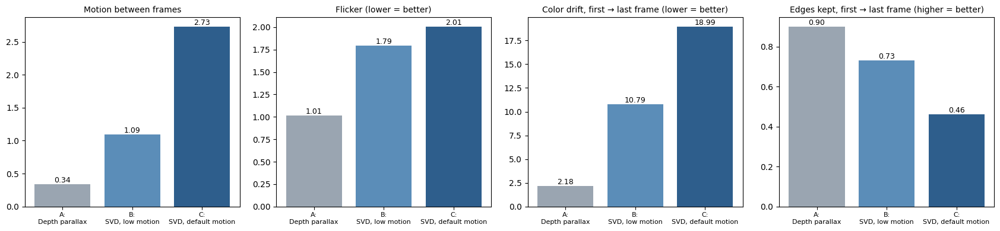

In [9]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
colors = ["#9AA5B1", "#5B8DB8", "#2E5E8C"]
labels = [m.replace(": ", ":\n") for m in NAMES]
for ax, col, title in zip(axes, ["motion (px/frame)", "flicker ΔE ↓", "drift ΔE ↓", "drift edge recall ↑"],
                          ["Motion between frames", "Flicker (lower = better)",
                           "Color drift, first → last frame (lower = better)", "Edges kept, first → last frame (higher = better)"]):
    ax.bar(labels, summary[col], color=colors)
    for i, v in enumerate(summary[col]): ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(title, fontsize=10); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.savefig("exp9_video.png", dpi=150); plt.show()

**What I saw.**
- A (depth parallax): faithful and fast (flicker 1.0, drift 2.2, 0.8 s per clip), but it barely moves (0.34 px per frame): with my settings the camera move is too small to feel like a video.
- B (SVD, low motion): the camera moves in slowly; the room stays recognisable, but the first frame already differs from the render (ΔE 4.7) and flicker is higher than parallax (1.8).
- C (SVD, default motion): the liveliest clip (2.7 px per frame) with the most flicker (2.0). Drift looks large (ΔE 19.0, edge recall 0.46), but the frames show that this is mostly a strong camera move towards the furniture, with parts of the room leaving the frame. Furniture, lamps and paintings stay the same type and place; smaller changes appear, such as the shape of a sofa and shelf objects.

**Result.** SVD keeps the room recognisable and mostly moves the camera, but it already changes the first frame, and more motion means more flicker. My drift metric could not separate a large camera move from a real design change, so for video the numbers need the frames next to them. Depth parallax is faithful but needs a stronger camera move to be useful.

## Download

In [10]:
df.to_csv("exp9_metrics.csv", index=False)
!zip -q exp9_results.zip exp9_*.gif exp9_*.jpg exp9_*.png exp9_metrics.csv
files.download("exp9_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>